# Exploratory Data Analysis - Smart Finance Tracker

Four sections, each ending in **Findings and Decisions**. Data: synthetic multi-user history from `src/data_prep.py`
(calibrated with MoSPI HCES 2023-24 urban shares). Public datasets #1-#3 are compared when present in `data/raw/`.

> Run `python -m src.data_prep` first.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_prep import load_public, EXPENSE_CATEGORIES, HCES_URBAN_SHARES
from src import features as F
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 140)
RES = ROOT / 'results'; RES.mkdir(exist_ok=True)
df = pd.read_csv(ROOT / 'data/processed/transactions_clean.csv', parse_dates=['date'])
users = pd.read_csv(ROOT / 'data/raw/users.csv')
labels = pd.read_csv(ROOT / 'data/raw/recurring_labels.csv')
public = load_public()
print(df.shape, users.shape, labels.shape)

[load_public] hf_transactions.csv not found in data/raw/ - skipping (see data/SOURCES.md)
[load_public] upi_transactions_2024.csv not found in data/raw/ - skipping (see data/SOURCES.md)
[load_public] credit_card_india.csv not found in data/raw/ - skipping (see data/SOURCES.md)
(377374, 13) (300, 4) (2626, 3)


## 1. Transactions

Imbalance ratio (largest / smallest class): 12.5


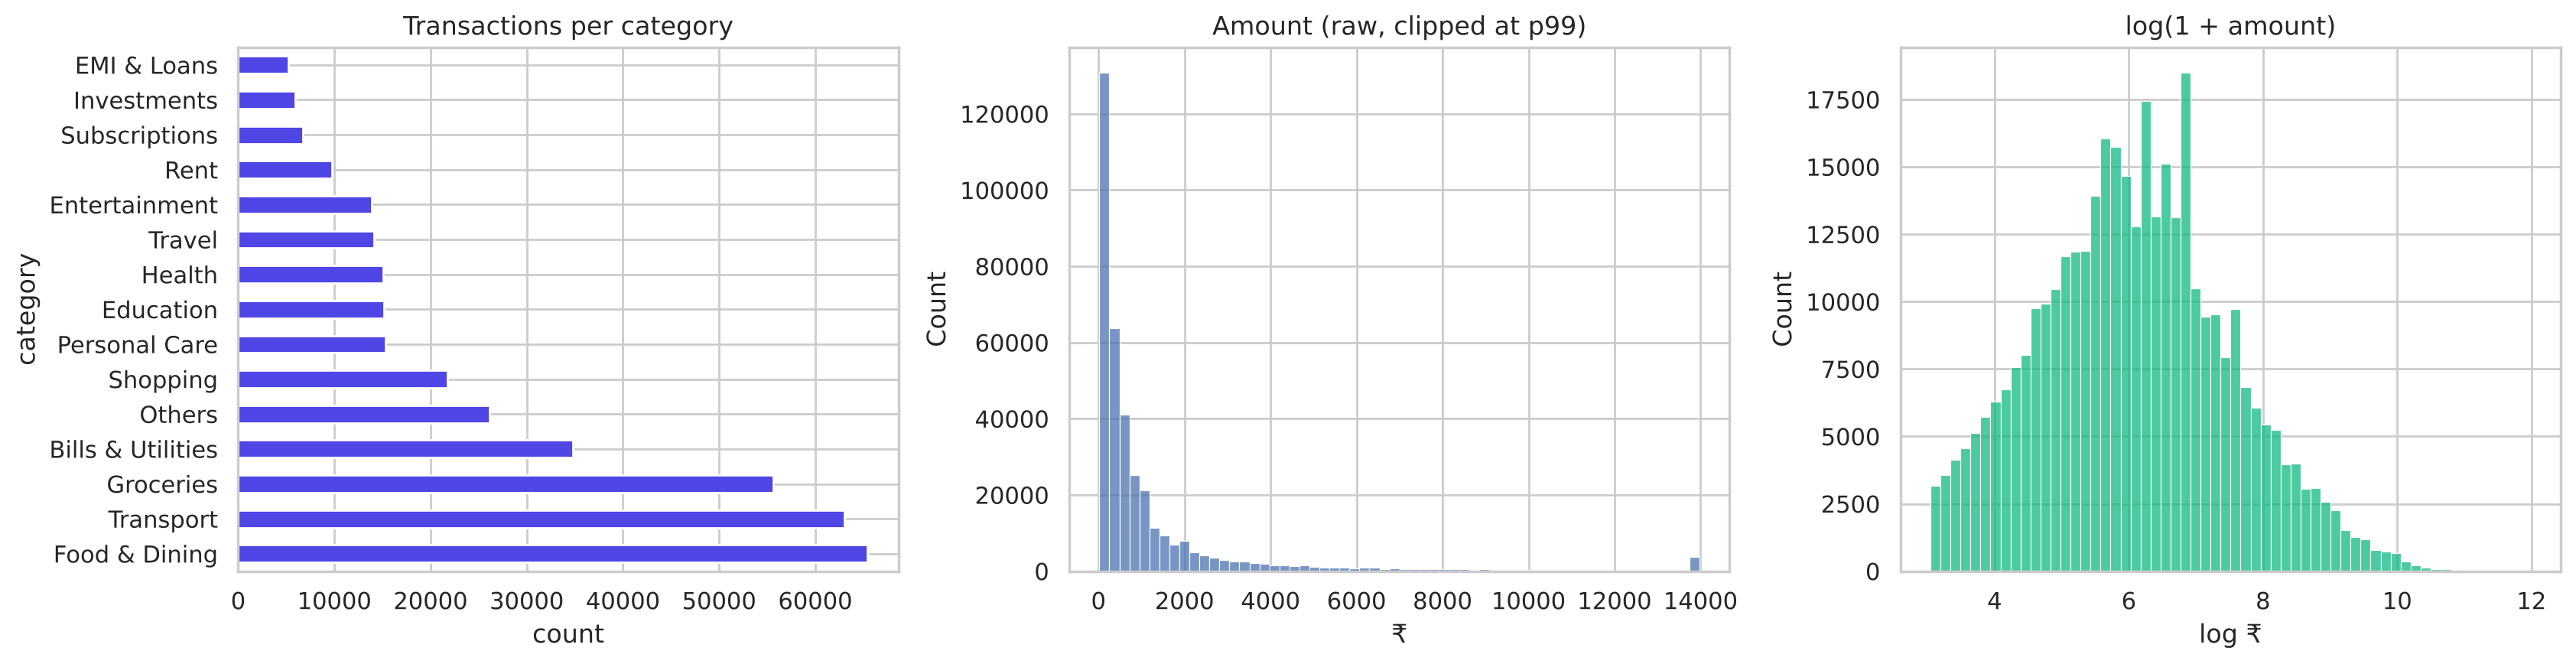

In [2]:
debit = df[df.type == 'debit']
counts = debit.category.value_counts()
print('Imbalance ratio (largest / smallest class):', round(counts.max() / counts.min(), 1))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
counts.plot.barh(ax=ax[0], color='#4F46E5'); ax[0].set(title='Transactions per category', xlabel='count')
sns.histplot(debit.amount.clip(upper=debit.amount.quantile(.99)), bins=60, ax=ax[1]); ax[1].set(title='Amount (raw, clipped at p99)', xlabel='₹')
sns.histplot(debit.log_amount, bins=60, ax=ax[2], color='#10B981'); ax[2].set(title='log(1 + amount)', xlabel='log ₹')
plt.tight_layout(); plt.savefig(RES / 'eda_category_counts_amounts.png', dpi=110); plt.show()

In [3]:
print('Payment mode share:'); print(df.payment_mode.value_counts(normalize=True).round(3))
print('\nMissing values:'); print(df.isna().sum()[df.isna().sum() > 0])
print('Exact duplicate rows:', df.duplicated(subset=['user_id','date','description','amount']).sum())
print('Rows whose cleaned description is "unknown":', (df.clean_desc == 'unknown').sum())

Payment mode share:
payment_mode
UPI      0.581
CARD     0.166
POS      0.166
ACH      0.030
NEFT     0.019
ATM      0.017
OTHER    0.013
IMPS     0.008
Name: proportion, dtype: float64

Missing values:
Series([], dtype: int64)
Exact duplicate rows: 0
Rows whose cleaned description is "unknown": 0


In [4]:
from collections import Counter
top = {c: [w for w, _ in Counter(' '.join(g.clean_desc).split()).most_common(5)] for c, g in debit.groupby('category')}
pd.DataFrame(top).T

,0,1,2,3,4
Bills & Utilities,airtel,gas,jio,bescom,xstream
EMI & Loans,loan,hdfc,bank,emi,tata
Education,fees,byjus,coursera,unacademy,udemy
Entertainment,pvr,inox,bookmyshow,wonderla,smaaash
Food & Dining,kfc,starbucks,zomato,mcdonalds,chaayos
Groceries,spencers,blinkit,bigbasket,dmart,jiomart
Health,medplus,pharmeasy,practo,thyrocare,1mg
Investments,mf,sip,groww,axis,zerodha
Others,atm,amazon,gift,paytm,donation
Personal Care,salon,fit,cult,purplle,nykaa


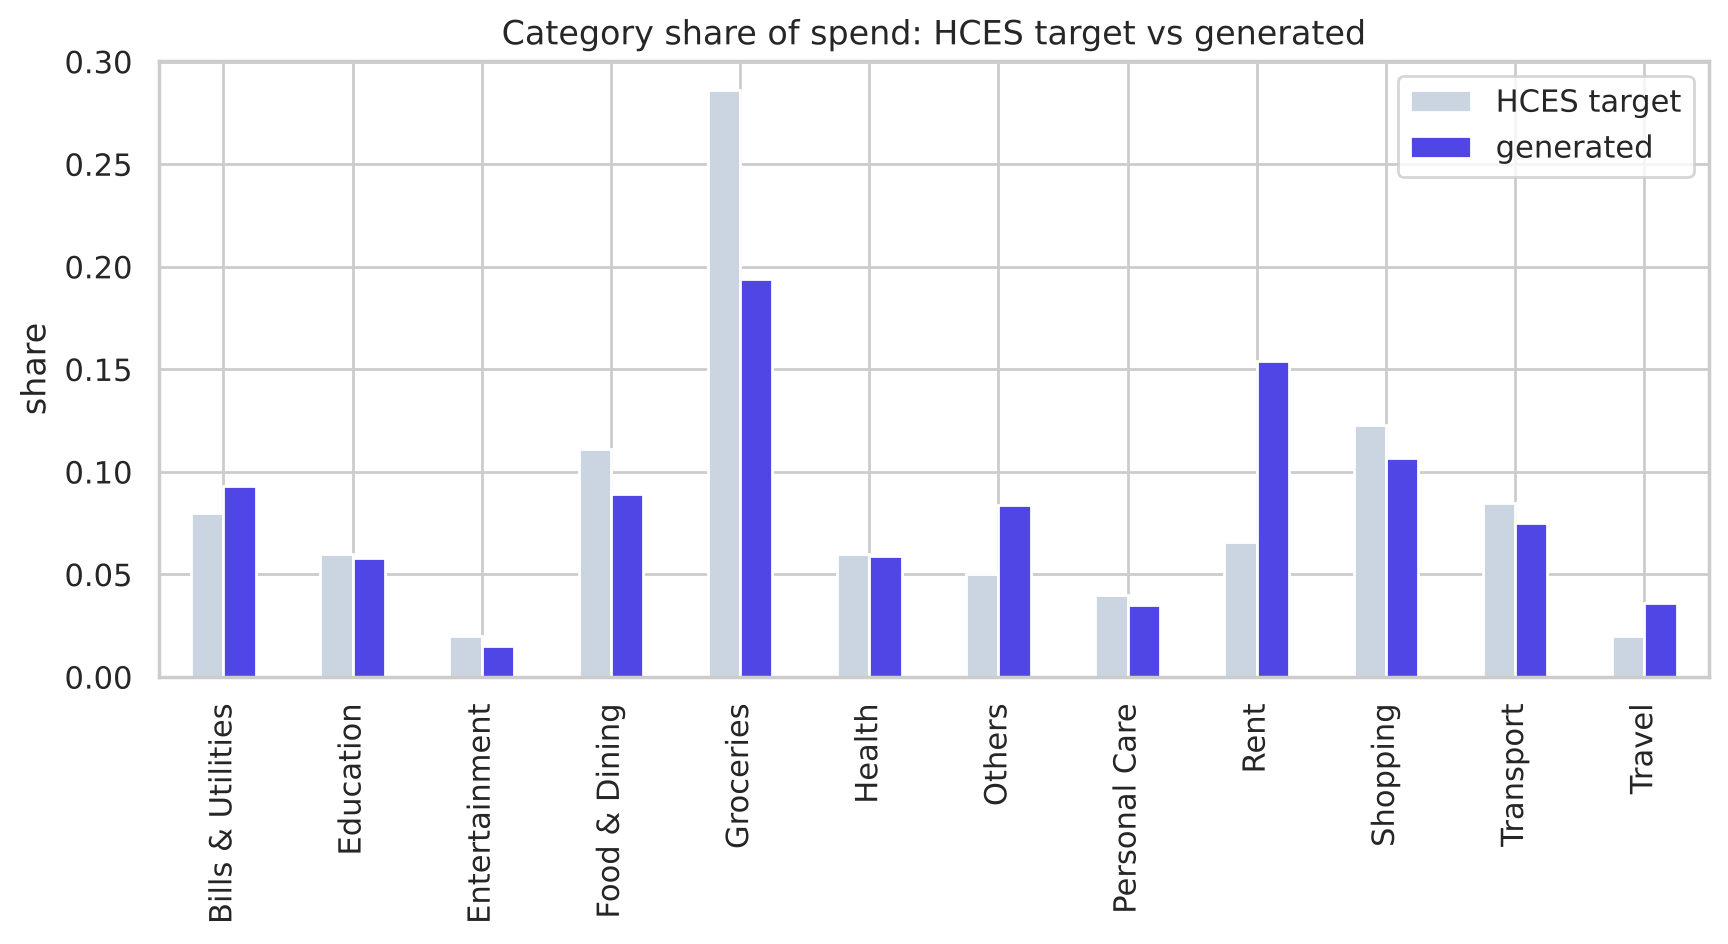

,HCES target,generated
Bills & Utilities,0.080,0.093
Education,0.060,0.058
Entertainment,0.020,0.015
Food & Dining,0.111,0.089
Groceries,0.286,0.194
Health,0.060,0.059
Others,0.050,0.084
Personal Care,0.040,0.035
Rent,0.066,0.154
Shopping,0.123,0.107


In [5]:
# share of spend vs HCES-based target (urban)
target = pd.Series(HCES_URBAN_SHARES); target /= target.sum()
actual = debit[debit.category.isin(target.index)].groupby('category').amount.sum(); actual /= actual.sum()
cmp = pd.DataFrame({'HCES target': target, 'generated': actual}).round(3)
cmp.plot.bar(figsize=(10, 4), color=['#CBD5E1', '#4F46E5'], title='Category share of spend: HCES target vs generated'); plt.ylabel('share'); plt.show()
cmp

In [6]:
# Comparison with public datasets (#1 HF transactions, #2 UPI 2024) when downloaded
for name, p in public.items():
    print(name, p.shape); display(p.head())
    num = p.select_dtypes('number')
    if len(num.columns): display(num.describe().T.head(5))
if not public:
    print('No public datasets in data/raw/ - download them to compare (see data/SOURCES.md).')

No public datasets in data/raw/ - download them to compare (see data/SOURCES.md).


### Findings and Decisions
**What I saw**
- 15 expense categories, **imbalanced**: Food & Dining has ~12.5× more transactions than the smallest category (EMI & Loans). Accuracy alone would be misleading.
- Amounts are heavily right-skewed (rent, EMIs, one-off purchases); `log(1 + amount)` is close to symmetric.
- UPI dominates (~58% of rows), then card and POS; ACH/NACH appears almost only for EMIs, SIPs and insurance, so payment mode carries category signal.
- No missing values or exact duplicates after cleaning; reference numbers and VPAs are removed, so no description collapses to `unknown`.
- Top tokens per category are merchant names, but ~5% of rows are person-to-person UPI payments (`UPI/RAHUL SHARMA/...`) whose text says nothing about the category.
- Generated spend shares track HCES for most groups. Rent is higher (15% vs 6.6%) because HCES averages in homeowners, and Groceries is correspondingly lower.

**Decisions**
- Primary metric **macro F1**. Compare `class_weight="balanced"` and **SMOTE** (inside the pipeline) against no reweighting.
- Features: word 1-2-gram + **character 2-5-gram TF-IDF** (robust to typos and truncation), `log_amount`, payment mode, day of week.
- Use a **confidence threshold** so ambiguous P2P payments are flagged *Needs review* instead of silently mislabelled.
- Large amounts are **flagged, not deleted** (rent is not an outlier).

## 2. Subscriptions

rows: 28612  positive share: 0.066


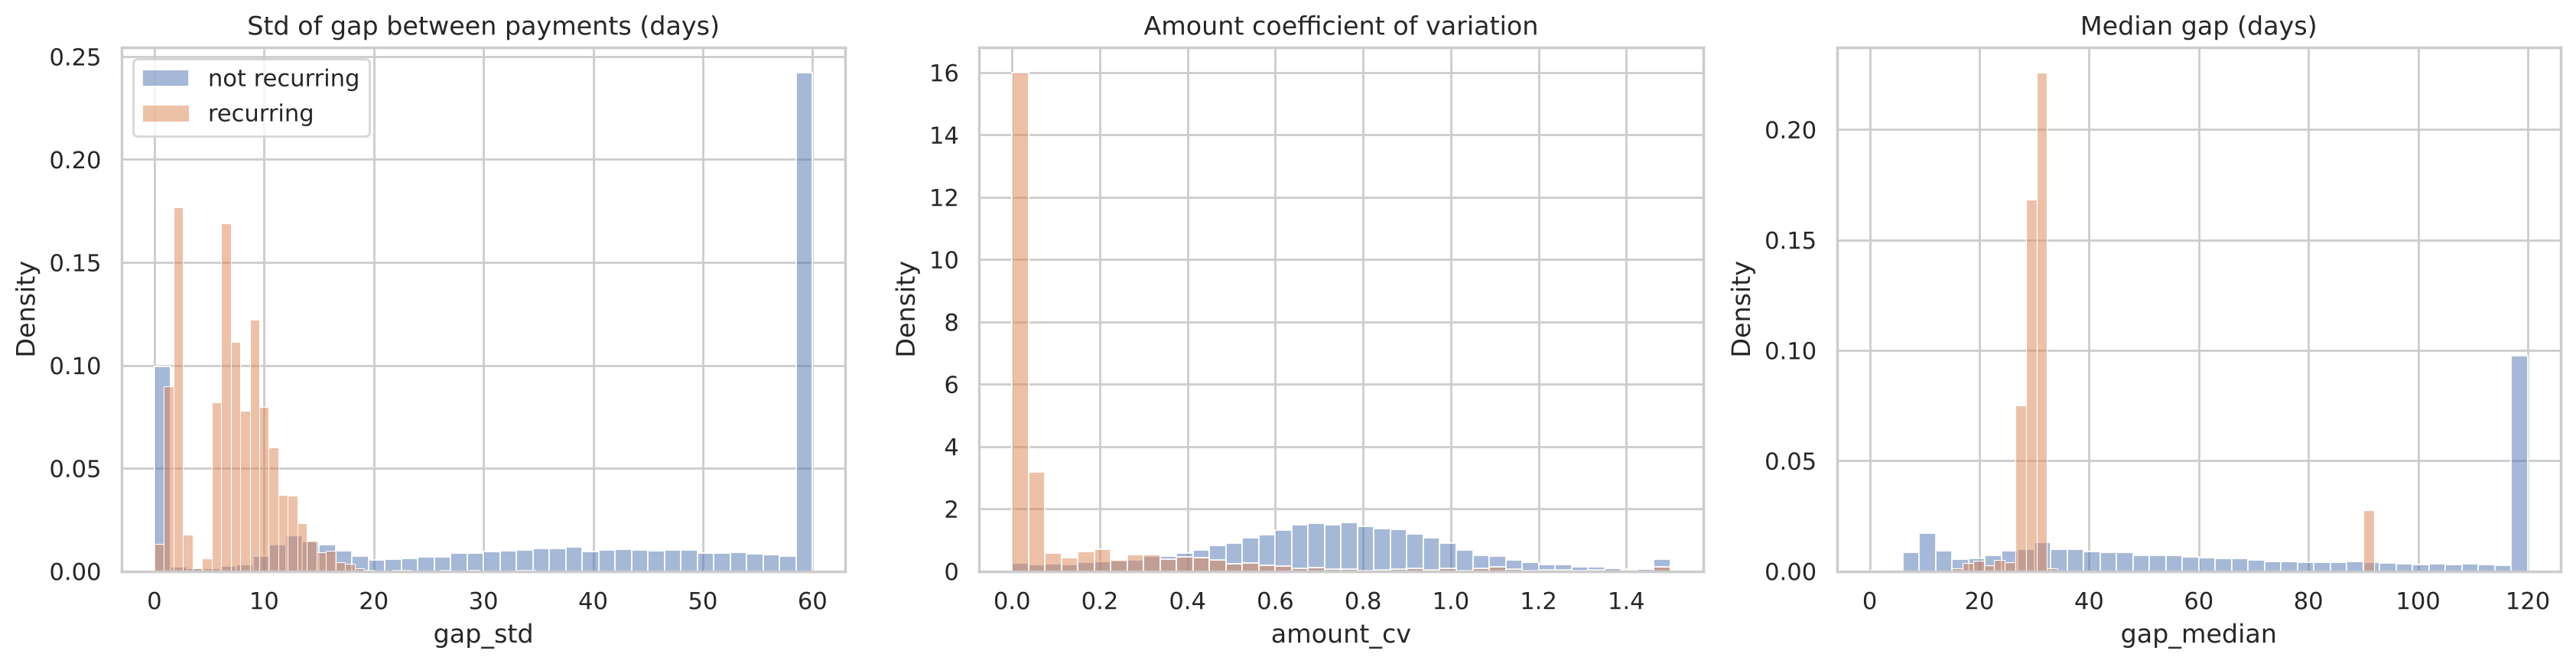

is_recurring,0,1
n_payments,6.000,23.000
gap_mean,83.143,31.000
gap_median,63.500,30.000
gap_std,43.487,7.032
gap_cv,0.727,0.228
amount_mean,546.127,998.169
amount_cv,0.728,0.003
same_amount_share,0.038,1.000
dom_std,8.000,1.435
months_active,6.000,23.000


In [7]:
sub = F.subscription_features(df).merge(labels, on=['user_id','merchant'], how='left')
sub['is_recurring'] = sub.is_recurring.fillna(0).astype(int)
print('rows:', len(sub), ' positive share:', round(sub.is_recurring.mean(), 3))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for k, g in sub.groupby('is_recurring'):
    lab = 'recurring' if k else 'not recurring'
    sns.histplot(g.gap_std.clip(upper=60), bins=40, ax=ax[0], label=lab, stat='density', alpha=.5)
    sns.histplot(g.amount_cv.clip(upper=1.5), bins=40, ax=ax[1], label=lab, stat='density', alpha=.5)
    sns.histplot(g.gap_median.clip(upper=120), bins=40, ax=ax[2], label=lab, stat='density', alpha=.5)
ax[0].set(title='Std of gap between payments (days)'); ax[1].set(title='Amount coefficient of variation'); ax[2].set(title='Median gap (days)')
ax[0].legend(); plt.tight_layout(); plt.savefig(RES / 'eda_subscription_features.png', dpi=110); plt.show()
sub.groupby('is_recurring')[F.SUB_FEATURES].median().T.round(3)

In [8]:
print('Hard negatives (non-recurring with near-fixed amounts):')
print(sub[(sub.is_recurring == 0) & (sub.same_amount_share > .8) & (sub.n_payments >= 3)].merchant.value_counts().head(8))
print('\nHard positives (recurring with varying amounts or irregular gaps):')
print(sub[(sub.is_recurring == 1) & ((sub.amount_cv > .05) | (sub.gap_std > 10))].merchant.value_counts().head(8))

Hard negatives (non-recurring with near-fixed amounts):
merchant
HP GAS          59
INDANE GAS      48
AMAZON PAY      29
BMTC            22
PAYTM WALLET    19
FASTAG          18
DELHI METRO     13
AMAZON           2
Name: count, dtype: int64

Hard positives (recurring with varying amounts or irregular gaps):
merchant
AIRTEL POSTPAID    103
AIRTEL              85
AIRTEL XSTREAM      80
CULT FIT            58
ACT FIBERNET        57
JIO                 53
SONYLIV             44
HOTSTAR             43
Name: count, dtype: int64


### Findings and Decisions
**What I saw**
- ~28.6k (user, merchant) groups with ≥2 payments; only **6.6% are recurring**, so the problem is strongly imbalanced.
- Recurring payments have small gap std (median ~7 days vs ~43), near-zero amount CV and `same_amount_share` ≈ 1.
- Hard negatives exist: LPG refills, wallet and FASTag top-ups have **fixed amounts but irregular timing**. Hard positives: postpaid and broadband bills with varying amounts, 28-day prepaid cycles, missed months, recently started subscriptions.

**Decisions**
- Use both **timing** (gap mean/median/std/CV, day-of-month std, longest missing stretch) and **amount** features (CV, same-amount share), because neither alone separates hard cases.
- Primary metric **F1 on the positive class**, plus PR-AUC (better than ROC-AUC under imbalance). Compare class weights / `scale_pos_weight` / **SMOTE**.
- CV **grouped by user** so the same person never appears in both train and validation.
- The near-perfect separation in this synthetic data is a warning sign: report it as an upper bound, not real-world performance.

## 3. Monthly spending

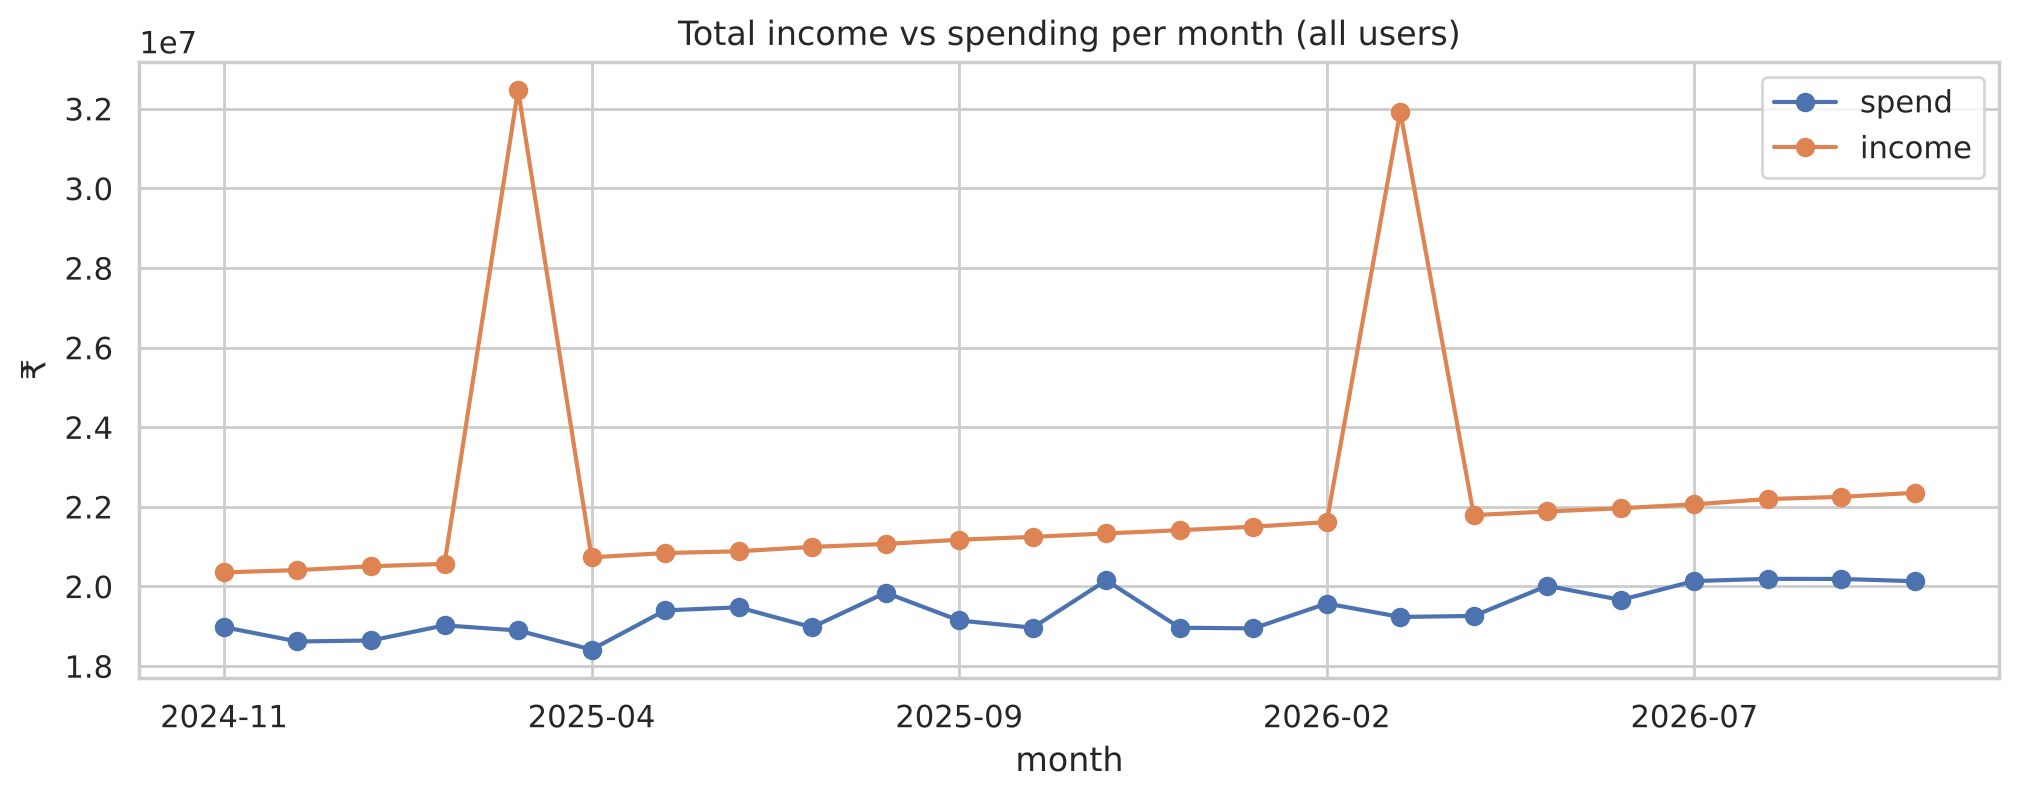

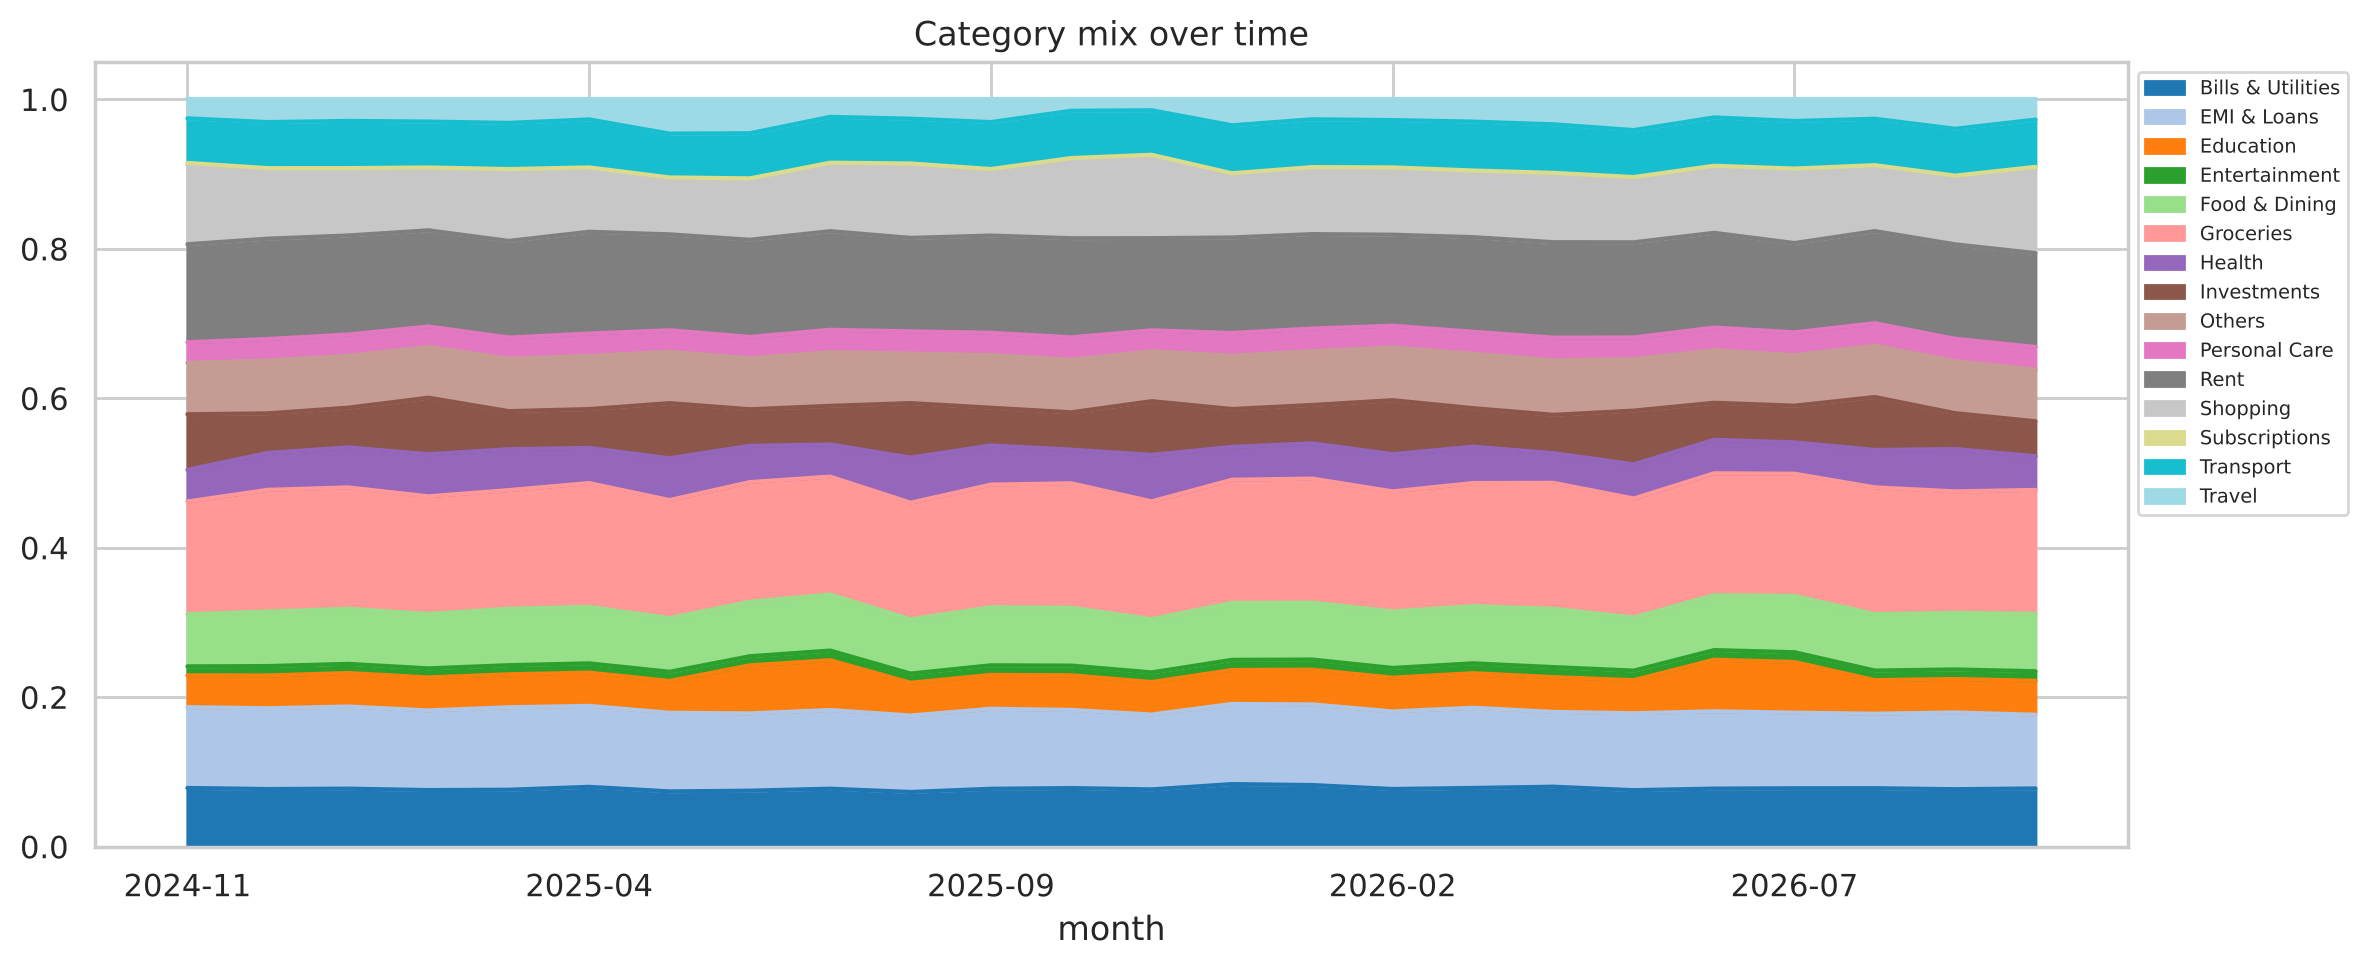

In [9]:
m = F.monthly_table(df)
tot = m.groupby('month').agg(spend=('spend', 'sum')).join(m.drop_duplicates(['user_id','month']).groupby('month').income.sum())
tot.index = tot.index.astype(str)
tot.plot(figsize=(12, 4), marker='o', title='Total income vs spending per month (all users)'); plt.ylabel('₹'); plt.show()
cat_trend = m.groupby(['month', 'category']).spend.sum().unstack()
cat_trend.index = cat_trend.index.astype(str)
(cat_trend / cat_trend.sum(axis=1).values[:, None]).plot.area(figsize=(12, 5), cmap='tab20', title='Category mix over time')
plt.legend(bbox_to_anchor=(1, 1), fontsize=7); plt.tight_layout(); plt.savefig(RES / 'eda_category_mix.png', dpi=110); plt.show()

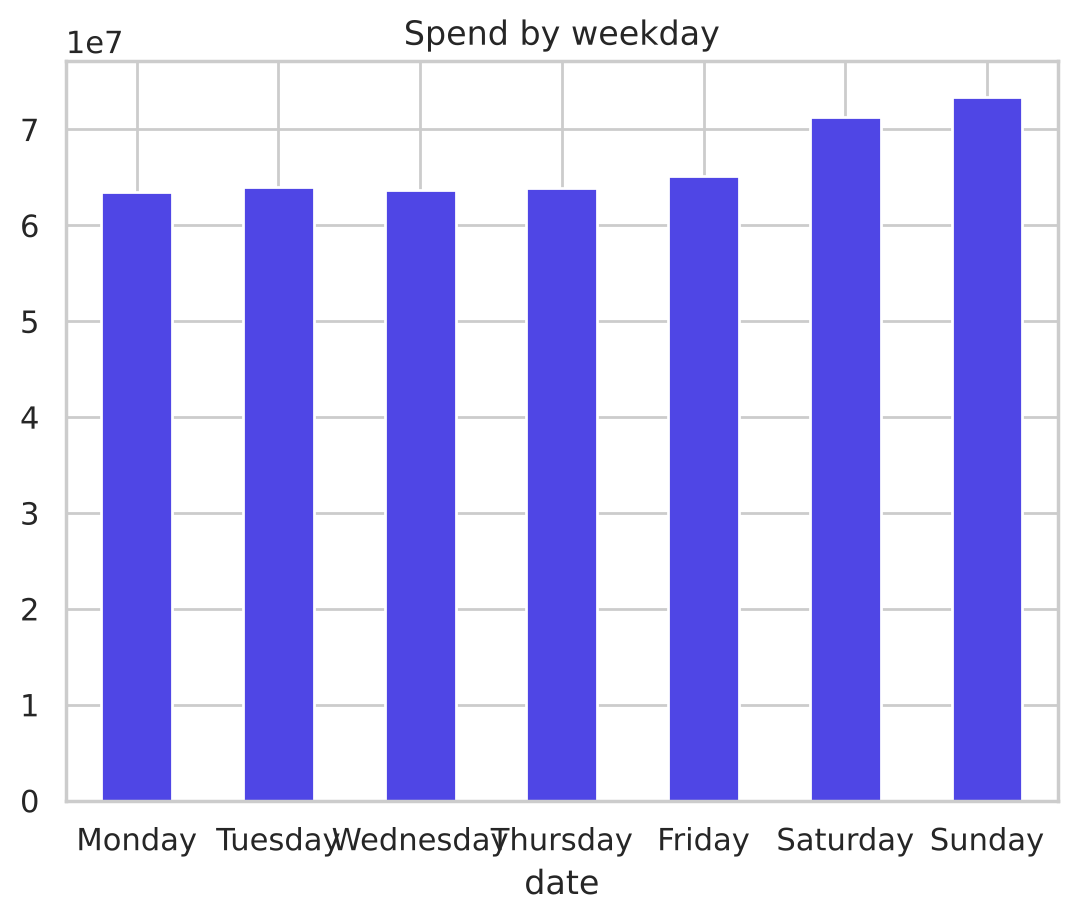

Correlation of next-month spend with lags:
target        1.000
lag1          0.773
lag2          0.770
lag3          0.773
lag12         0.797
roll3_mean    0.837
Name: target, dtype: float64

Lag-1 autocorrelation by category:
category
Travel               0.02
Health               0.10
Shopping             0.43
Transport            0.87
Education            0.89
Investments          0.90
Bills & Utilities    0.90
Rent                 0.92
Others               0.93
Groceries            0.94
Personal Care        0.94
Subscriptions        0.94
Food & Dining        0.95
Entertainment        0.96
EMI & Loans          0.98
dtype: float64


In [10]:
wd = df[df.type == 'debit'].groupby(df.date.dt.day_name()).amount.sum()
wd.reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']).plot.bar(title='Spend by weekday', color='#4F46E5', rot=0); plt.show()
ff = F.forecast_features(m)
corr = ff[['target', 'lag1', 'lag2', 'lag3', 'lag12', 'roll3_mean']].corr()['target'].round(3)
print('Correlation of next-month spend with lags:'); print(corr)
per_cat = ff.groupby('category').apply(lambda g: g['target'].corr(g['lag1']), include_groups=False).sort_values()
print('\nLag-1 autocorrelation by category:'); print(per_cat.round(2))

### Findings and Decisions
**What I saw**
- Totals grow slowly over 24 months (income trend), with mild seasonality: Shopping in Oct-Nov, Travel in May/Dec, Education in Jun-Jul.
- Next-month spend correlates with lag 1, 2 and 3 (~0.77 each), more with the **3-month rolling mean (0.84)** and with **lag 12 (0.80)**.
- Lag-1 autocorrelation is very high for fixed or regular categories (EMI 0.98, Subscriptions 0.94, Rent 0.92) and very low for lumpy ones (**Travel 0.02, Health 0.10, Shopping 0.43**), which are the hardest to forecast.
- Discretionary categories are spent more on weekends.

**Decisions**
- Features: lags 1-3, rolling 3-month mean/std, **same-month-last-year** (with a has-lag-12 flag), transaction count, average ticket, income, spend-to-income ratio, target month as sin/cos, and category one-hot.
- Two baselines: last month and 3-month mean (the stronger one, as EDA predicts). Use a chronological split.
- Expect large per-category errors for Travel/Health/Shopping and show a forecast range (validation residual quantiles).

## 4. Users

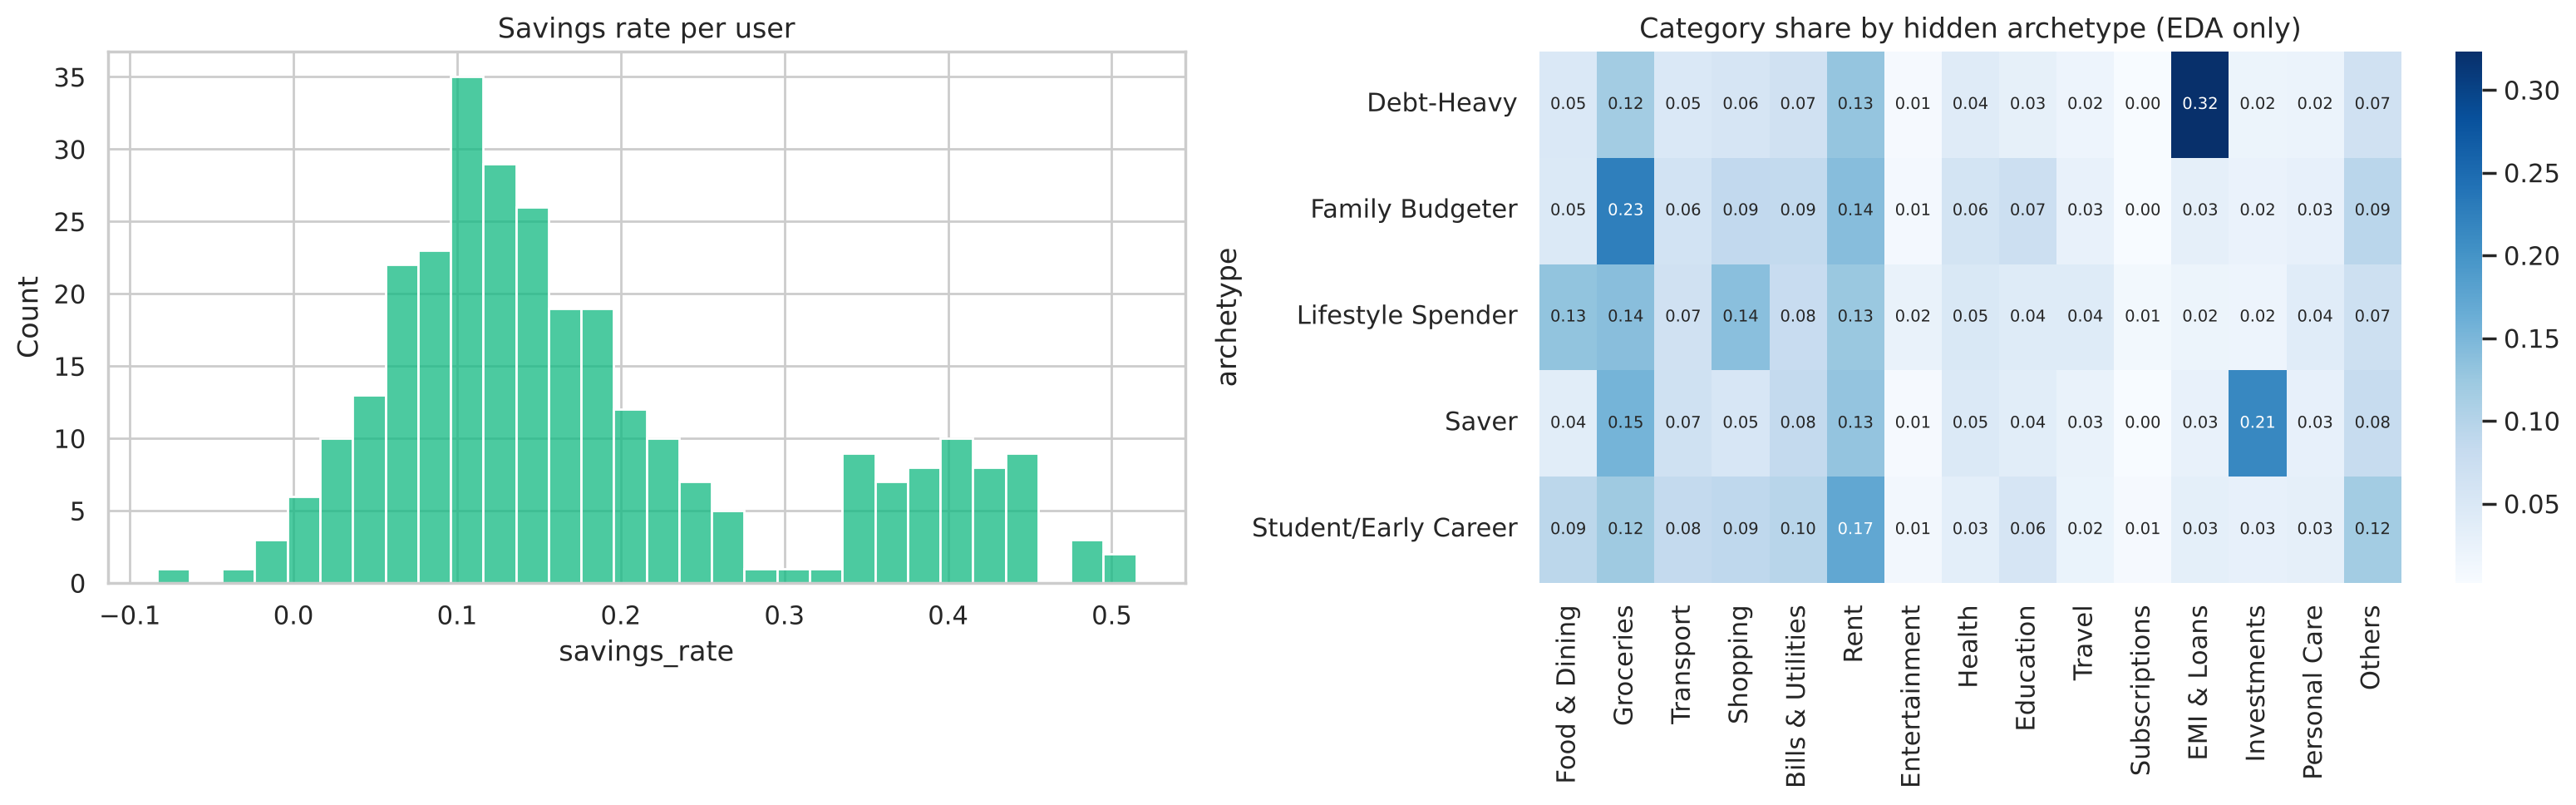

In [11]:
pf = F.persona_features(df).merge(users, on='user_id')
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(pf.savings_rate, bins=30, ax=ax[0], color='#10B981'); ax[0].set(title='Savings rate per user')
share = pf.groupby('archetype')[F.PERSONA_SHARE_COLS].mean(); share.columns = [c.replace('share_', '') for c in share.columns]
sns.heatmap(share, cmap='Blues', ax=ax[1], annot=True, fmt='.2f', annot_kws={'size': 7}); ax[1].set(title='Category share by hidden archetype (EDA only)')
plt.tight_layout(); plt.show()

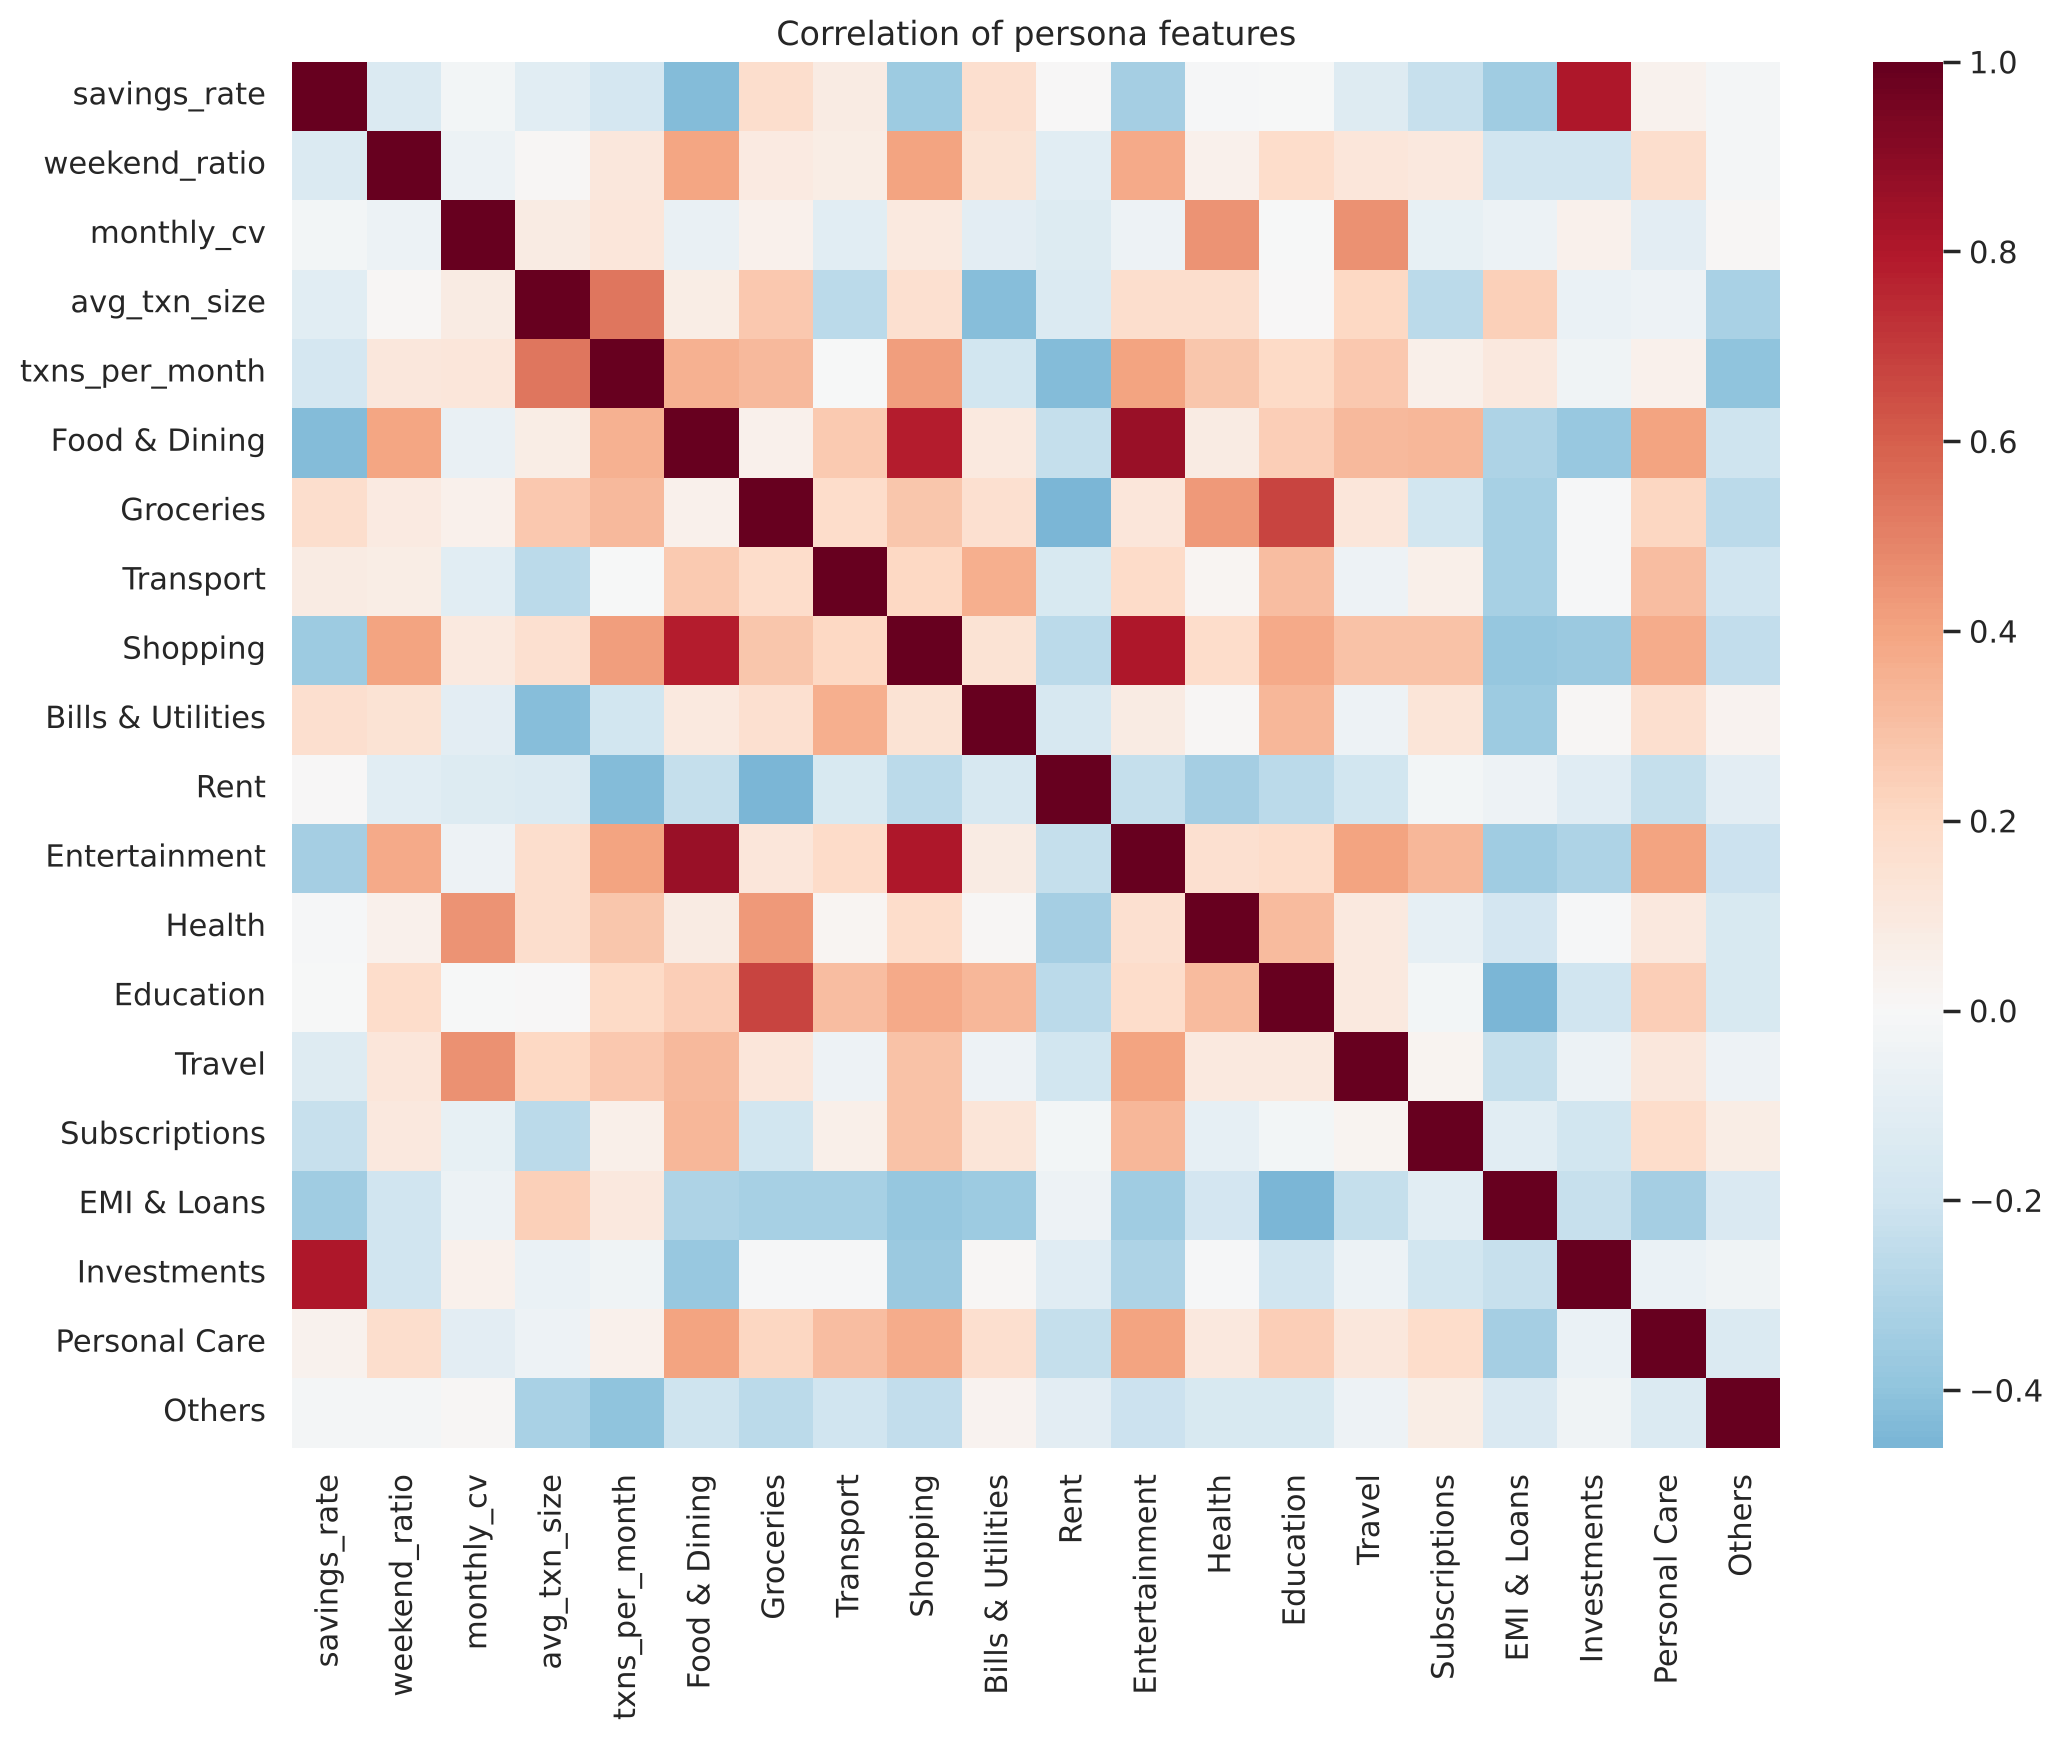

Skewness:
savings_rate      0.87
weekend_ratio     0.14
monthly_cv       -0.09
avg_txn_size      1.17
txns_per_month   -0.84
dtype: float64


In [12]:
plt.figure(figsize=(12, 9))
sns.heatmap(pf[F.PERSONA_FEATURES].corr(), cmap='RdBu_r', center=0, xticklabels=[c.replace('share_', '') for c in F.PERSONA_FEATURES],
            yticklabels=[c.replace('share_', '') for c in F.PERSONA_FEATURES]); plt.title('Correlation of persona features'); plt.show()
print('Skewness:'); print(pf[F.PERSONA_NUM].skew().round(2))

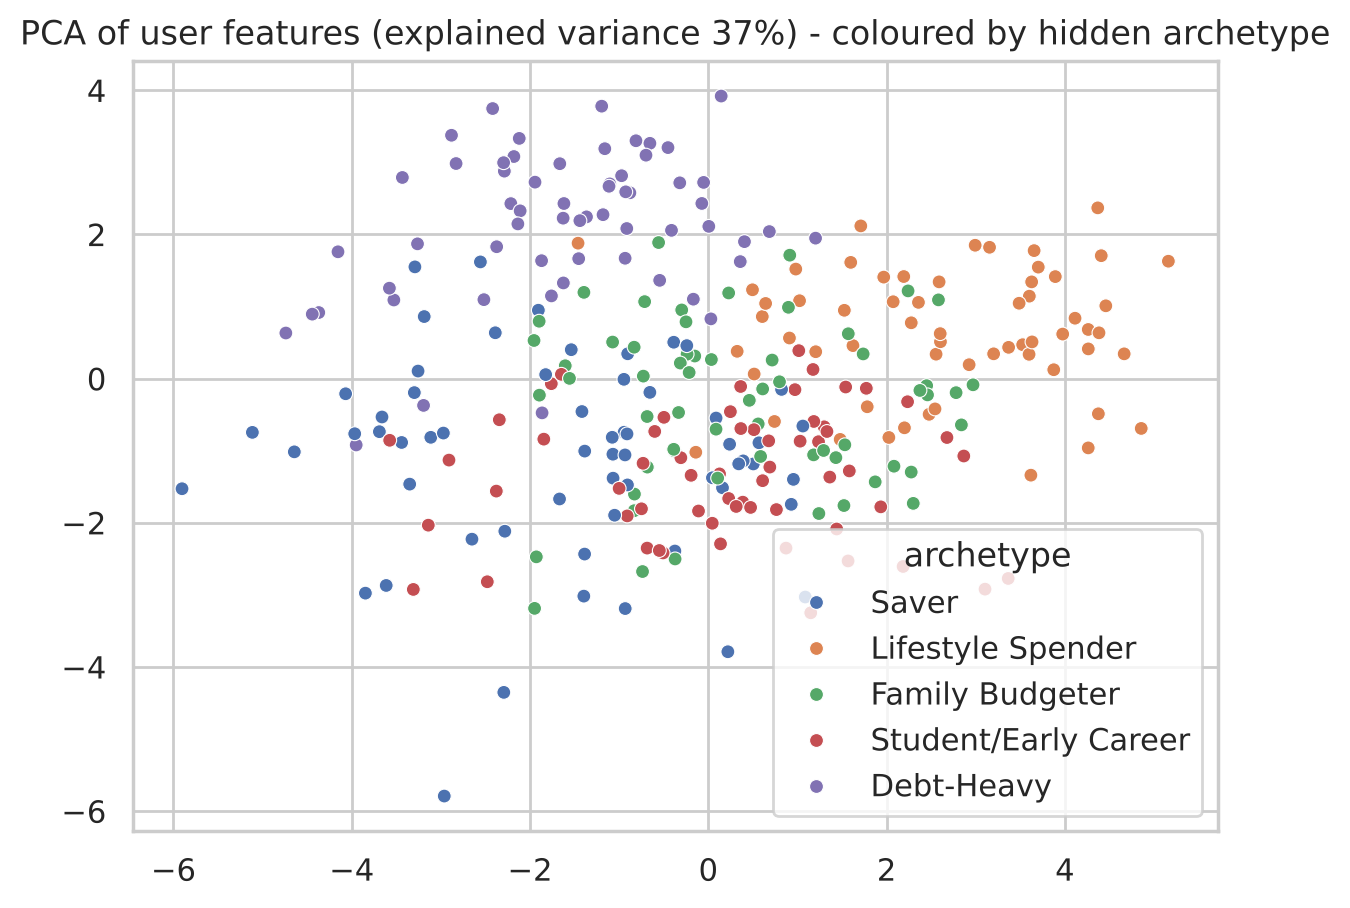

In [13]:
from sklearn.decomposition import PCA
X = F.persona_preprocessor().fit_transform(pf[F.PERSONA_FEATURES])
pca = PCA(2).fit(X); pc = pca.transform(X)
plt.figure(figsize=(7, 5)); sns.scatterplot(x=pc[:, 0], y=pc[:, 1], hue=pf.archetype, s=25)
plt.title(f'PCA of user features (explained variance {pca.explained_variance_ratio_.sum():.0%}) - coloured by hidden archetype')
plt.savefig(RES / 'eda_users_pca.png', dpi=110); plt.show()

### Findings and Decisions
**What I saw**
- Savings rate ranges from about 0 to 45% and is right-skewed (skew 0.87). Average ticket size is also skewed (1.17).
- Category shares differ clearly by (hidden) archetype: EMI share for Debt-Heavy, Investments for Savers, Dining/Shopping/Travel for Lifestyle Spenders, Education/Groceries for Family Budgeters.
- Several share features are correlated (for example Dining with Entertainment), but none is redundant enough to drop.
- In the 2-D PCA projection, archetypes form visible but overlapping groups.

**Decisions**
- Log-transform skewed features (average ticket, transactions per month, weekend ratio), then `StandardScaler`, all inside one pipeline.
- Try K-Means, Gaussian Mixture and Agglomerative for k = 2-8, selecting on **silhouette**. Reject solutions with a cluster under 5% of users, and require k ≥ 3 so personas are useful.
- Archetypes are used **only** for a post-hoc ARI check, never as features.